# Diabetes, BMI & Cholesterol in NHANES: An Exploratory Health Analysis
**Rajneesh Jaswal**

## Overview
An end-to-end exploratory analysis of the NHANES health survey (10,000 records, 76 variables). I audit missing data against CDC survey eligibility rules, handle duplicates and outliers, explore the distributions, use simulation to demonstrate the central limit theorem, and then look at two questions:

1. How do BMI and total cholesterol differ between adults who report diabetes and those who don't?
2. How do diabetes prevalence and cholesterol differ between current/former smokers and never smokers?

### Key findings (adults aged 20+)
- Adults reporting diabetes have a **higher mean BMI** (31.9 vs 28.3 kg/m²); **55% have BMI > 30**, compared with 33% of those without diabetes.
- They also have **lower mean total cholesterol** (4.81 vs 5.08 mmol/L).
- Reported diabetes is **more common among current/former smokers** (13.0% vs 10.3%), while mean cholesterol is nearly identical between the two smoking groups.
- These are unadjusted associations, not causal effects. Limitations are listed in the conclusion.

## Import Libraries
I import the libraries used to organise the data, calculate statistics, create visualizations, and generate random samples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import math

In [2]:
# Show all columns, but keep long tables manageable.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

## Load the Dataset
I load the NHANES dataset and preview the first five rows to check its initial structure.

In [3]:
# Load the dataset and preview the first five rows.
nhanes_raw = pd.read_csv("data/nhanes.csv")
nhanes_raw.head()

,ID,SurveyYr,Gender,Age,AgeDecade,AgeMonths,Race1,Race3,Education,MaritalStatus,HHIncome,HHIncomeMid,Poverty,HomeRooms,HomeOwn,Work,Weight,Length,HeadCirc,Height,BMI,BMICatUnder20yrs,BMI_WHO,Pulse,BPSysAve,BPDiaAve,BPSys1,BPDia1,BPSys2,BPDia2,BPSys3,BPDia3,Testosterone,DirectChol,TotChol,UrineVol1,UrineFlow1,UrineVol2,UrineFlow2,Diabetes,DiabetesAge,HealthGen,DaysPhysHlthBad,DaysMentHlthBad,LittleInterest,Depressed,nPregnancies,nBabies,Age1stBaby,SleepHrsNight,SleepTrouble,PhysActive,PhysActiveDays,TVHrsDay,CompHrsDay,TVHrsDayChild,CompHrsDayChild,Alcohol12PlusYr,AlcoholDay,AlcoholYear,SmokeNow,Smoke100,Smoke100n,SmokeAge,Marijuana,AgeFirstMarij,RegularMarij,AgeRegMarij,HardDrugs,SexEver,SexAge,SexNumPartnLife,SexNumPartYear,SameSex,SexOrientation,PregnantNow
0,51624,2009_10,male,34,30-39,409.0,White,NaN,High School,Married,25000-34999,30000.0,1.36,6.0,Own,NotWorking,87.4,NaN,NaN,164.7,32.22,NaN,30.0_plus,70.0,113.0,85.0,114.0,88.0,114.0,88.0,112.0,82.0,NaN,1.29,3.49,352.0,NaN,NaN,NaN,No,NaN,Good,0.0,15.0,Most,Several,NaN,NaN,NaN,4.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Yes,NaN,0.0,No,Yes,Smoker,18.0,Yes,17.0,No,NaN,Yes,Yes,16.0,8.0,1.0,No,Heterosexual,NaN
1,51624,2009_10,male,34,30-39,409.0,White,NaN,High School,Married,25000-34999,30000.0,1.36,6.0,Own,NotWorking,87.4,NaN,NaN,164.7,32.22,NaN,30.0_plus,70.0,113.0,85.0,114.0,88.0,114.0,88.0,112.0,82.0,NaN,1.29,3.49,352.0,NaN,NaN,NaN,No,NaN,Good,0.0,15.0,Most,Several,NaN,NaN,NaN,4.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Yes,NaN,0.0,No,Yes,Smoker,18.0,Yes,17.0,No,NaN,Yes,Yes,16.0,8.0,1.0,No,Heterosexual,NaN
2,51624,2009_10,male,34,30-39,409.0,White,NaN,High School,Married,25000-34999,30000.0,1.36,6.0,Own,NotWorking,87.4,NaN,NaN,164.7,32.22,NaN,30.0_plus,70.0,113.0,85.0,114.0,88.0,114.0,88.0,112.0,82.0,NaN,1.29,3.49,352.0,NaN,NaN,NaN,No,NaN,Good,0.0,15.0,Most,Several,NaN,NaN,NaN,4.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Yes,NaN,0.0,No,Yes,Smoker,18.0,Yes,17.0,No,NaN,Yes,Yes,16.0,8.0,1.0,No,Heterosexual,NaN
3,51625,2009_10,male,4,0-9,49.0,Other,NaN,NaN,NaN,20000-24999,22500.0,1.07,9.0,Own,NaN,17.0,NaN,NaN,105.4,15.30,NaN,12.0_18.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,51630,2009_10,female,49,40-49,596.0,White,NaN,Some College,LivePartner,35000-44999,40000.0,1.91,5.0,Rent,NotWorking,86.7,NaN,NaN,168.4,30.57,NaN,30.0_plus,86.0,112.0,75.0,118.0,82.0,108.0,74.0,116.0,76.0,NaN,1.16,6.70,77.0,0.094,NaN,NaN,No,NaN,Good,0.0,10.0,Several,Several,2.0,2.0,27.0,8.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Yes,2.0,20.0,Yes,Yes,Smoker,38.0,Yes,18.0,No,NaN,Yes,Yes,12.0,10.0,1.0,Yes,Heterosexual,NaN


## 1. Dataset overview
I first checked the number of rows, columns, data types and missing values. The input file has 10,000 rows and 76 columns.

In [4]:
table_detail = pd.DataFrame({'Total rows':[nhanes_raw.shape[0]], 'Total columns/variables':[nhanes_raw.shape[1]]})
display(table_detail.style.hide(axis='index'))

Total rows,Total columns/variables
10000,76


In [5]:
# Summarise data types and missingness across all variables.
table_summery = pd.DataFrame({'Variable Names':[col for col in nhanes_raw.columns], 'Data Types':[col for col in nhanes_raw.dtypes],
                              'Total Non Missing':[i for i in nhanes_raw.notna().sum()],'Total Missing':[i for i in nhanes_raw.isna().sum()],
                              'Missing Perct':[i for i in nhanes_raw.isna().mean()*100], 'Distinct Values': nhanes_raw.nunique().to_list()}).sort_values(by='Missing Perct', ascending=False)
table_summery = table_summery.reset_index(drop=True)
display(table_summery)

,Variable Names,Data Types,Total Non Missing,Total Missing,Missing Perct,Distinct Values
0,HeadCirc,float64,88,9912,99.12,56
1,Length,float64,543,9457,94.57,309
2,DiabetesAge,float64,629,9371,93.71,72
3,CompHrsDayChild,float64,653,9347,93.47,7
4,TVHrsDayChild,float64,653,9347,93.47,7
5,BMICatUnder20yrs,str,1274,8726,87.26,4
6,AgeRegMarij,float64,1366,8634,86.34,36
7,Depressed,str,1427,8573,85.73,2
8,UrineFlow2,float64,1476,8524,85.24,760
9,UrineVol2,float64,1478,8522,85.22,294


## 2. Selected Variables
I selected the variables needed for the analysis, with a focus on diabetes, BMI, cholesterol, and smoking history. I kept the original dataset unchanged.

ID identifies a participant and is not treated as a numerical measurement. The file contains 6,779 distinct participant IDs across 10,000 rows. Repeated records are retained at this stage and examined later.

In [6]:
# Keep the original data unchanged and work with the selected variables.
nhanes_selected = nhanes_raw[[
    'ID', 'AgeDecade', 'SurveyYr', 'Gender', 'Age',
    'Pulse', 'Height', 'Weight', 'Poverty',
    'Education', 'MaritalStatus', 'HomeOwn',
    'Smoke100', 'SmokeNow', 'BPSysAve', 'BMI', 'Diabetes', 'TotChol'
]].copy()
nhanes_selected.head()

,ID,AgeDecade,SurveyYr,Gender,Age,Pulse,Height,Weight,Poverty,Education,MaritalStatus,HomeOwn,Smoke100,SmokeNow,BPSysAve,BMI,Diabetes,TotChol
0,51624,30-39,2009_10,male,34,70.0,164.7,87.4,1.36,High School,Married,Own,Yes,No,113.0,32.22,No,3.49
1,51624,30-39,2009_10,male,34,70.0,164.7,87.4,1.36,High School,Married,Own,Yes,No,113.0,32.22,No,3.49
2,51624,30-39,2009_10,male,34,70.0,164.7,87.4,1.36,High School,Married,Own,Yes,No,113.0,32.22,No,3.49
3,51625,0-9,2009_10,male,4,NaN,105.4,17.0,1.07,NaN,NaN,Own,NaN,NaN,NaN,15.30,No,NaN
4,51630,40-49,2009_10,female,49,86.0,168.4,86.7,1.91,Some College,LivePartner,Rent,Yes,Yes,112.0,30.57,No,6.70


In [7]:
# Summarise data types and missingness in the selected working dataset.
selected_summery = pd.DataFrame({'Variable Names':[col for col in nhanes_selected.columns], 'Data Types':[col for col in nhanes_selected.dtypes],
                              'Total Non Missing':[i for i in nhanes_selected.notna().sum()],'Total Missing':[i for i in nhanes_selected.isna().sum()],
                              'Missing Perct':[i for i in nhanes_selected.isna().mean()*100], 'Distinct Values': nhanes_selected.nunique().to_list()}).sort_values(by='Missing Perct', ascending=False)
display(selected_summery)

,Variable Names,Data Types,Total Non Missing,Total Missing,Missing Perct,Distinct Values
13,SmokeNow,str,3211,6789,67.89,2
9,Education,str,7221,2779,27.79,5
10,MaritalStatus,str,7231,2769,27.69,6
12,Smoke100,str,7235,2765,27.65,2
17,TotChol,float64,8474,1526,15.26,250
14,BPSysAve,float64,8551,1449,14.49,126
5,Pulse,float64,8563,1437,14.37,47
8,Poverty,float64,9274,726,7.26,450
15,BMI,float64,9634,366,3.66,2073
6,Height,float64,9647,353,3.53,980


In [8]:
# Identify columns that contain missing values for further investigation
missing_col = []
for col in nhanes_selected.columns:
  if nhanes_selected[col].isna().any():
    missing_col.append(col)
print(missing_col)


['AgeDecade', 'Pulse', 'Height', 'Weight', 'Poverty', 'Education', 'MaritalStatus', 'HomeOwn', 'Smoke100', 'SmokeNow', 'BPSysAve', 'BMI', 'Diabetes', 'TotChol']


## 3. Check Missing Values by Age
I compared AgeDecade with Age and found that all 333 missing AgeDecade entries have a recorded age of 80. In this dataset, 80 represents participants aged 80 or older. I assigned these missing entries to the existing 70+ category without changing their recorded Age.

In [9]:
# Create a temporary age grouping to locate missing AgeDecade entries.
nhanes_selected['AgeDecade_check'] = pd.cut(nhanes_selected['Age'], bins=[0,9,19,29,39,49,59,69,80],labels=['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69','70+'],include_lowest=True)
table_example = pd.crosstab(nhanes_selected['AgeDecade_check'], nhanes_selected['AgeDecade'].isna(),dropna=False).rename(columns={False:'not_missing', True:'missing'})
table_example

AgeDecade,not_missing,missing
AgeDecade_check,,
0-9,1391,0
10-19,1374,0
20-29,1356,0
30-39,1338,0
40-49,1398,0
50-59,1304,0
60-69,919,0
70+,587,333


In [10]:
# Check the recorded ages of participants with missing AgeDecade
nhanes_selected[['Age']][nhanes_selected['AgeDecade'].isna()].value_counts()


Age
80     333
Name: count, dtype: int64

In [11]:
# The missing AgeDecade entries checked above are all age 80.
# Use 70+ as my combined group for ages 70 and above.
nhanes_selected = nhanes_selected.drop(columns=['AgeDecade_check'])
nhanes_selected['AgeDecade'] = nhanes_selected['AgeDecade'].str.strip()
nhanes_selected.loc[nhanes_selected['AgeDecade'].isna() & (nhanes_selected['Age'] >= 70),'AgeDecade'] = '70+'

In [12]:
# Examine missing-value patterns across age groups.
for col in missing_col:
  if col == 'AgeDecade':
    continue
  table_example = pd.crosstab(nhanes_selected['AgeDecade'], nhanes_selected[col].isna(),dropna=False).rename(columns={False:'not_missing', True:'missing'})
  print(f"Missing values in {col} by age decade\n")
  display(table_example)
  print('\n')

Missing values in Pulse by age decade



Pulse,not_missing,missing
AgeDecade,,
0-9,257,1134
10-19,1325,49
20-29,1309,47
30-39,1269,69
40-49,1360,38
50-59,1262,42
60-69,891,28
70+,890,30




Missing values in Height by age decade



Height,not_missing,missing
AgeDecade,,
0-9,1102,289
10-19,1363,11
20-29,1350,6
30-39,1334,4
40-49,1386,12
50-59,1299,5
60-69,911,8
70+,902,18




Missing values in Weight by age decade



Weight,not_missing,missing
AgeDecade,,
0-9,1383,8
10-19,1361,13
20-29,1346,10
30-39,1334,4
40-49,1387,11
50-59,1298,6
60-69,909,10
70+,904,16


... (16 outputs left out)



Missing values in Diabetes by age decade



Diabetes,not_missing,missing
AgeDecade,,
0-9,1254,137
10-19,1371,3
20-29,1356,0
30-39,1338,0
40-49,1398,0
50-59,1304,0
60-69,917,2
70+,920,0




Missing values in TotChol by age decade



TotChol,not_missing,missing
AgeDecade,,
0-9,415,976
10-19,1214,160
20-29,1257,99
30-39,1273,65
40-49,1354,44
50-59,1234,70
60-69,873,46
70+,854,66


## 4. Age-Related and Conditional Missingness
I checked the age eligibility and questionnaire skip rules in the NHANES documentation. For categorical variables, I label age-ineligible responses as “Not applicable.” SmokeNow is not asked when Smoke100 is No, so I label those entries separately as “Not asked.”

These labels explain why a response is absent; they do not add observed answers. Numeric measurements remain NaN to preserve their numeric data types. Missing responses among eligible participants are considered separately.

In [13]:
# Label missing entries for under-20s without changing observed answers.
nhanes_selected.loc[
    (nhanes_selected['Age'] < 20) & nhanes_selected['Smoke100'].isna(),
    'Smoke100'
] = 'Not applicable: under 20'

In [14]:
# Check SmokeNow missingness against the lifetime-smoking response.
smoke_now_table = pd.crosstab(nhanes_selected['Smoke100'], nhanes_selected['SmokeNow'].isna(),dropna=False).rename(columns={False:'not_missing', True:'missing'})
smoke_now_table

SmokeNow,not_missing,missing
Smoke100,,
No,0,4024
Not applicable: under 20,0,2765
Yes,3211,0


In [15]:
# Label missing SmokeNow responses for participants below the eligible age.
nhanes_selected.loc[
    (nhanes_selected['Age'] < 20) & nhanes_selected['SmokeNow'].isna(),'SmokeNow'] = 'Not applicable: under 20'

In [16]:
# Verify that only the skipped adult SmokeNow responses remain missing.
smoke_now_table1 = pd.crosstab(nhanes_selected['Smoke100'], nhanes_selected['SmokeNow'].isna(),dropna=False).rename(columns={False:'not_missing', True:'missing'})
smoke_now_table1

SmokeNow,not_missing,missing
Smoke100,,
No,0,4024
Not applicable: under 20,2765,0
Yes,3211,0


In [17]:
# The table shows SmokeNow is missing when Smoke100 is No.
# Keep this separate from an observed No answer to SmokeNow.
nhanes_selected.loc[
    (nhanes_selected['Smoke100'] == 'No') & nhanes_selected['SmokeNow'].isna(),
    'SmokeNow'
] = 'Not asked: Smoke100 = No'

In [18]:
# Keep age-related missing entries separate from other missing responses.
age_factor_col = ['Education', 'MaritalStatus']
for col in age_factor_col:
    nhanes_selected.loc[
        (nhanes_selected['Age'] < 20) & nhanes_selected[col].isna(), col
    ] = 'Not applicable: under 20'

In [19]:
# Diabetes is reported for ages 1+; label missing responses below that age.
nhanes_selected.loc[
    (nhanes_selected['Age'] == 0) & nhanes_selected['Diabetes'].isna(),'Diabetes'] = 'Not applicable: under 1'

# Keeping missing numeric measurements as NaN; did not replace them with zero.

### Check Missing Values After Labeling
The labels explain structural missingness but do not add observed responses. For example, “Not applicable” is not an education level, so I keep it separate from substantive answers in later comparisons.

In [20]:
# Recheck remaining missing values after labeling structural missingness.
missing_col1 = []
for col in nhanes_selected.columns:
  if nhanes_selected[col].isna().any():
    missing_col1.append(col)

for col in missing_col1:
  if col == 'AgeDecade':
    continue
  table_example1 = pd.crosstab(nhanes_selected['AgeDecade'], nhanes_selected[col].isna(),dropna=False).rename(columns={False:'not_missing', True:'missing'})
  print(f"Remaining missing values in {col} by age decade")
  display(table_example1)
  print('\n\n')
#

Remaining missing values in Pulse by age decade


Pulse,not_missing,missing
AgeDecade,,
0-9,257,1134
10-19,1325,49
20-29,1309,47
30-39,1269,69
40-49,1360,38
50-59,1262,42
60-69,891,28
70+,890,30





Remaining missing values in Height by age decade


Height,not_missing,missing
AgeDecade,,
0-9,1102,289
10-19,1363,11
20-29,1350,6
30-39,1334,4
40-49,1386,12
50-59,1299,5
60-69,911,8
70+,902,18





Remaining missing values in Weight by age decade


Weight,not_missing,missing
AgeDecade,,
0-9,1383,8
10-19,1361,13
20-29,1346,10
30-39,1334,4
40-49,1387,11
50-59,1298,6
60-69,909,10
70+,904,16


... (12 outputs left out)




Remaining missing values in Diabetes by age decade


Diabetes,not_missing,missing
AgeDecade,,
0-9,1391,0
10-19,1371,3
20-29,1356,0
30-39,1338,0
40-49,1398,0
50-59,1304,0
60-69,917,2
70+,920,0





Remaining missing values in TotChol by age decade


TotChol,not_missing,missing
AgeDecade,,
0-9,415,976
10-19,1214,160
20-29,1257,99
30-39,1273,65
40-49,1354,44
50-59,1234,70
60-69,873,46
70+,854,66


## 5. Missing Values by Age Eligibility
Overall missing percentages combine age-ineligible participants with eligible participants whose responses or measurements are unavailable. I therefore calculate missing percentages within each variable’s documented eligible age group and report remaining NaNs outside that group separately.

Categorical entries already labeled “Not applicable” are no longer counted as NaN, although they remain ineligible responses.

In [21]:
# Apply documented minimum-age eligibility for the missingness audit.
# Minimum age 0 means no age restriction for these selected variables.
# Eligibility rules do not justify filling unavailable measurements.
age_groups = {
    0: ['Weight', 'Poverty', 'HomeOwn'],
    1: ['Diabetes'],
    2: ['Height', 'BMI'],
    6: ['TotChol'],
    8: ['Pulse', 'BPSysAve'],
    20: ['Education', 'MaritalStatus']
}

results = []

for min_age, columns in age_groups.items():
    eligible = nhanes_selected.loc[nhanes_selected['Age'] >= min_age]
    outside = nhanes_selected.loc[nhanes_selected['Age'] < min_age]
    for col in columns:
        results.append({
            'Variable': col,
            'Minimum Age': min_age,
            'Eligible Rows': len(eligible),
            'Missing': eligible[col].isna().sum(),
            'Missing %': eligible[col].isna().mean() * 100,
            'Missing Outside Condition': outside[col].isna().sum()})

missing_summary = (pd.DataFrame(results).sort_values('Missing %', ascending=False).reset_index(drop=True))

display(missing_summary.round(2))

,Variable,Minimum Age,Eligible Rows,Missing,Missing %,Missing Outside Condition
0,TotChol,6,9149,675,7.38,851
1,Poverty,0,10000,726,7.26,0
2,BPSysAve,8,8870,319,3.60,1130
3,Pulse,8,8870,307,3.46,1130
4,BMI,2,9728,94,0.97,272
5,Height,2,9728,81,0.83,272
6,Weight,0,10000,78,0.78,0
7,HomeOwn,0,10000,63,0.63,0
8,Education,20,7235,14,0.19,0
9,MaritalStatus,20,7235,4,0.06,0


## 6. Working Subset
I excluded rows with remaining missing values in HomeOwn, Education, MaritalStatus, or Diabetes. This removed 85 rows (0.85%), leaving 9,915 rows in the working subset.

I retained nhanes_selected for reference. Structural “Not applicable” labels were preserved, and missing numeric measurements remained NaN. Although the excluded proportion is small, the removal may still introduce selection bias.

In [22]:
cols_to_na_removal = ['HomeOwn', 'Education', 'MaritalStatus', 'Diabetes']

nhanes_complete = nhanes_selected.dropna(subset=cols_to_na_removal).copy()
results = []

for min_age, columns in age_groups.items():
    eligible = nhanes_complete.loc[nhanes_complete['Age'] >= min_age]
    outside = nhanes_complete.loc[nhanes_complete['Age'] < min_age]
    for col in columns:
        results.append({
            'Variable': col,
            'Minimum Age': min_age,
            'Eligible Rows': len(eligible),
            'Missing': eligible[col].isna().sum(),
            'Missing %': eligible[col].isna().mean() * 100,
            'Missing Outside Condition': outside[col].isna().sum()})

missing_summary = (pd.DataFrame(results).sort_values('Missing %', ascending=False).reset_index(drop=True))

display(missing_summary.round(2))
# Report the actual row change instead of typing the result manually.
removed_rows = len(nhanes_selected) - len(nhanes_complete)
print(f'Rows before exclusion: {len(nhanes_selected)}')
print(f'Rows excluded: {removed_rows} ({removed_rows / len(nhanes_selected) * 100:.2f}%)')
print(f'Rows remaining: {len(nhanes_complete)}')

,Variable,Minimum Age,Eligible Rows,Missing,Missing %,Missing Outside Condition
0,TotChol,6,9067,668,7.37,848
1,Poverty,0,9915,658,6.64,0
2,BPSysAve,8,8790,311,3.54,1125
3,Pulse,8,8790,299,3.40,1125
4,BMI,2,9644,92,0.95,271
5,Height,2,9644,81,0.84,271
6,Weight,0,9915,76,0.77,0
7,HomeOwn,0,9915,0,0.00,0
8,Diabetes,1,9779,0,0.00,0
9,Education,20,7167,0,0.00,0


Rows before exclusion: 10000
Rows excluded: 85 (0.85%)
Rows remaining: 9915


## 7. Check Pulse and Blood Pressure Availability by Age
CDC documentation specifies that radial pulse and blood pressure are measured from age 8. I examine individual ages below 10 to check whether the recorded measurements follow this eligibility rule.

In [23]:
# Look at individual ages because the 0-9 group hides the age-8 boundary.
young_rows = nhanes_complete.loc[nhanes_complete['Age'] < 10]
for col in ['Pulse', 'BPSysAve']:
    age_table = pd.crosstab(
        young_rows['Age'], young_rows[col].isna(), dropna=False
    ).reindex(columns=[False, True], fill_value=0)
    age_table.columns = ['not_missing', 'missing']
    print(f'Missing values by age: {col}')
    display(age_table)

Missing values by age: Pulse


,not_missing,missing
Age,,
0,0,136
1,0,135
2,0,146
3,0,132
4,0,170
5,0,129
6,0,144
7,0,133
8,115,1


Missing values by age: BPSysAve


,not_missing,missing
Age,,
0,0,136
1,0,135
2,0,146
3,0,132
4,0,170
5,0,129
6,0,144
7,0,133
8,115,1


## Summary of Data Preparation
- The source dataset contains 10,000 rows and 76 columns. I preserved the raw data and selected 18 variables for analysis.
- I assigned 333 missing AgeDecade entries to the existing 70+ category. Their recorded Age is 80, representing ages 80 and older.
- I used documented age eligibility and smoking-question skip rules to label structural missingness in categorical variables.
- I excluded 85 rows (0.85%) with remaining missing values in HomeOwn, Education, MaritalStatus, or Diabetes, leaving 9,915 rows.
- Missing numeric measurements remain NaN and are excluded only from calculations requiring those measurements.

In [24]:
# Count repeated selected records, excluding the first occurrence.
nhanes_complete.duplicated(keep='first').sum()

np.int64(3194)

## Repeated Records
I removed 3,194 repeated records based on the 18 selected variables, retaining one occurrence of each combination. This left 6,721 rows.

This NHANES extract was resampled, so these repetitions are not necessarily errors. Removing them changes the sample composition and may affect the results.

In [25]:
nhanes_deduplicated = nhanes_complete.drop_duplicates().copy()

## Exploratory Data Analysis
I examine summary statistics and distributions for age, pulse, height, and weight. I also explore height–weight and income-to-poverty–weight relationships, followed by contingency tables for education versus smoking and marital status versus home ownership.

In [26]:
# Provide summary statistics for age, pulse, height, and weight.
summary_stats = nhanes_deduplicated[['Age', 'Pulse', 'Height', 'Weight']].describe().round(2)
display(summary_stats)

,Age,Pulse,Height,Weight
count,6721.00,5605.00,6424.00,6667.00
mean,35.43,73.63,160.35,69.08
std,23.12,12.23,21.15,29.98
min,0.00,40.00,83.60,2.80
25%,15.00,64.00,155.50,53.35
50%,34.00,72.00,165.10,71.20
75%,54.00,82.00,173.70,87.60
max,80.00,136.00,200.40,230.70


### Interpretation of Summary Statistics
The dataset contains 6,721 records before outlier removal. Mean age is 35.43 years, with a median of 34. Recorded age 80 includes participants aged 80 and older.

Mean pulse is 73.63 beats per minute, based on 5,605 available measurements. Mean height is 160.35 cm, and mean weight is 69.08 kg. These measurements combine children and adults, so they should not be interpreted as adult averages.

Height’s mean is below its median of 165.10 cm, consistent with shorter children contributing to the lower end of the distribution. Histograms will help assess the shapes more clearly. Observation counts differ because of age eligibility and missing measurements.

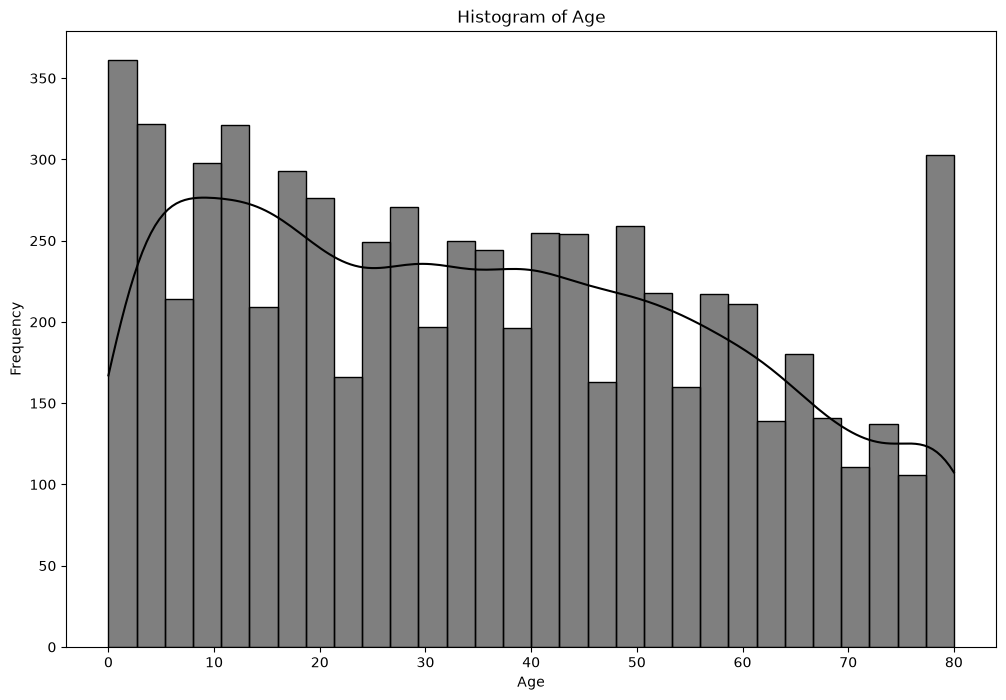

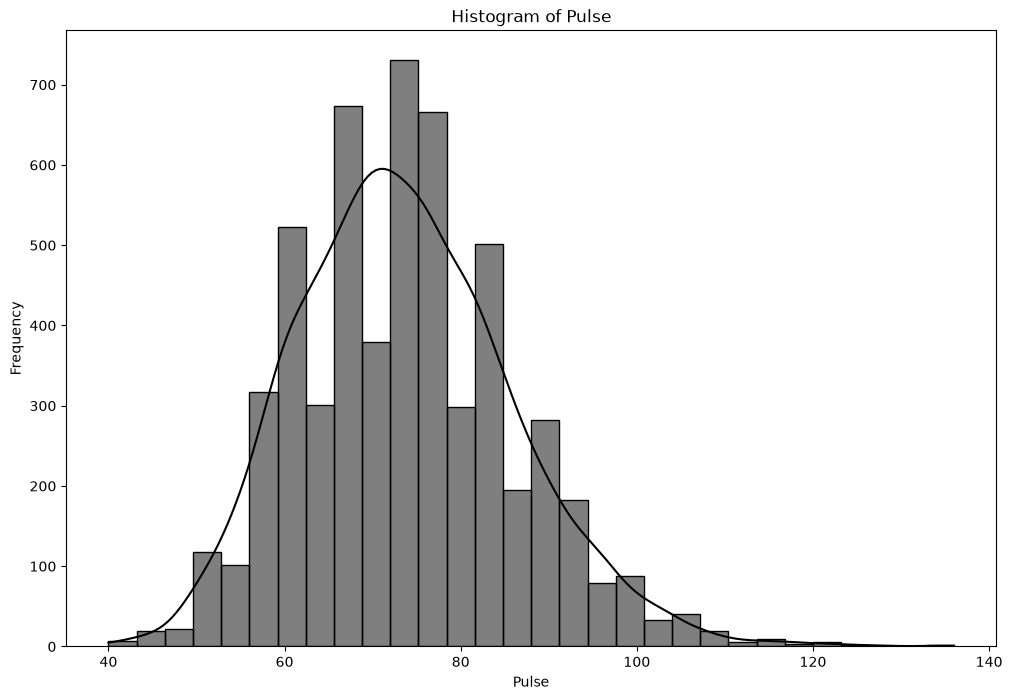

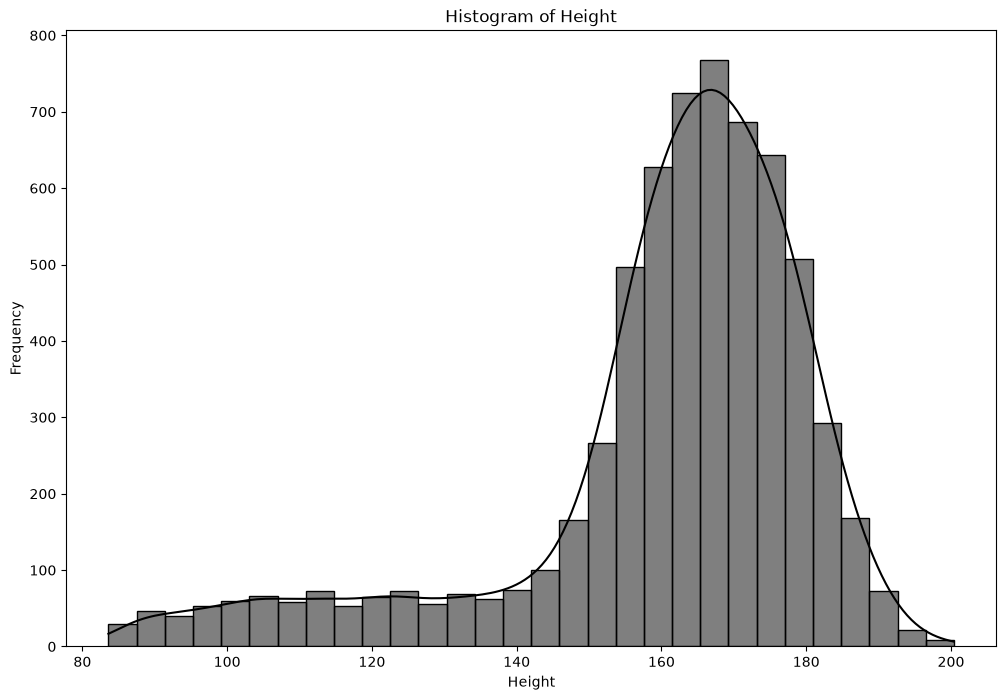

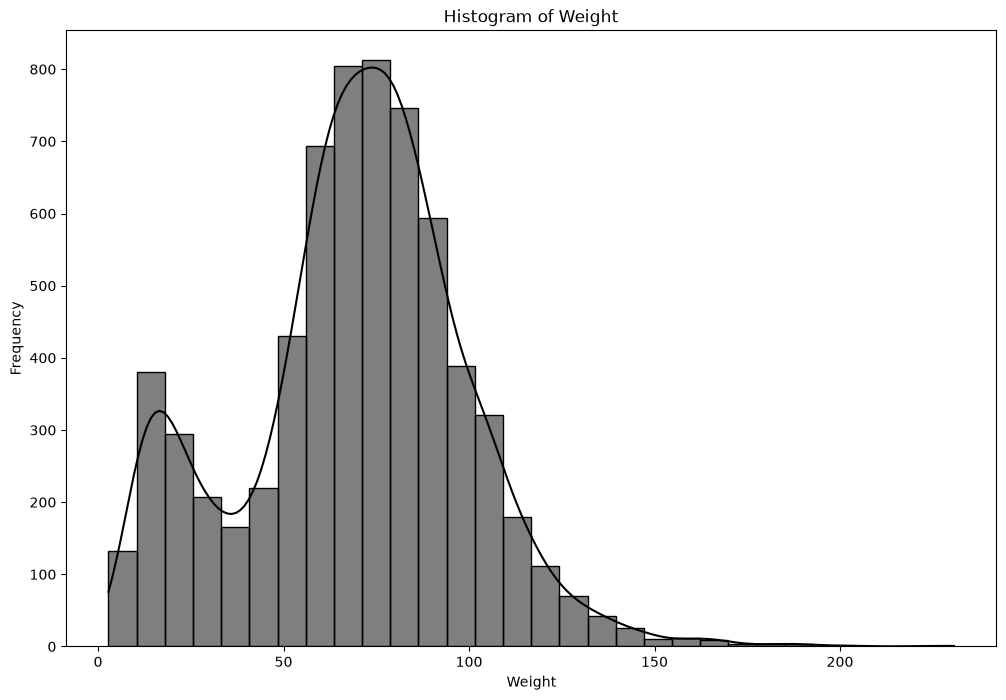

In [27]:
# Create histograms  for age, pulse, height, and weight.
variables = ['Age', 'Pulse', 'Height', 'Weight']
for i in variables:
    plt.figure(figsize=(12, 8))
    sns.histplot(nhanes_deduplicated[i], kde=True, bins=30, color='black')
    plt.title(f'Histogram of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

### Interpretation of Histograms
- **Age — Discrete as recorded:** Age is recorded in whole years. The distribution is uneven and does not appear normal. The higher frequency at 80 partly reflects grouping everyone aged 80 or older together.
- **Pulse — Discrete as recorded:** Pulse values are derived from counted heartbeats and expressed in beats per minute. The distribution is roughly bell-shaped around 70–75, with a longer right tail, so it is not perfectly normal.
- **Height — Continuous:** Height is measured in centimetres. Most observations cluster around 160–180 cm, with a long left tail. Including children alongside adults helps explain the shorter heights. The overall distribution does not appear normal.
- **Weight — Continuous:** Weight is measured in kilograms. There is a main peak around 70–80 kg, a smaller peak at lower weights, and a long right tail. The pooled distribution does not appear normal.

These assessments are based on visual inspection. The smoothed curves help show the shapes but do not prove normality.

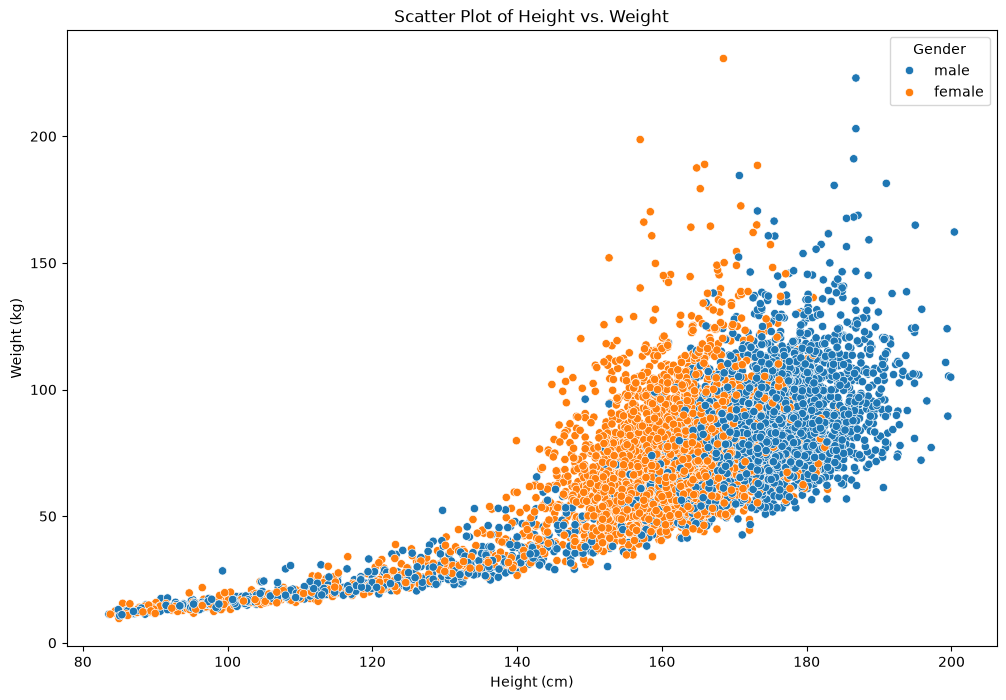

In [28]:
# Generate scatter plots for the height vs. weight
plt.figure(figsize=(12, 8))
sns.scatterplot(data=nhanes_deduplicated, x='Height', y='Weight', hue='Gender')
plt.title('Scatter Plot of Height vs. Weight')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.show()

### Height and Weight
The scatterplot shows a positive relationship: taller participants generally weigh more. The pattern is curved, and weight varies more widely at taller heights.

Male participants tend to appear in the taller range, although the two groups overlap considerably. Because the dataset includes both children and adults, growth and age differences contribute to the overall pattern. The plot shows an association, not causation.

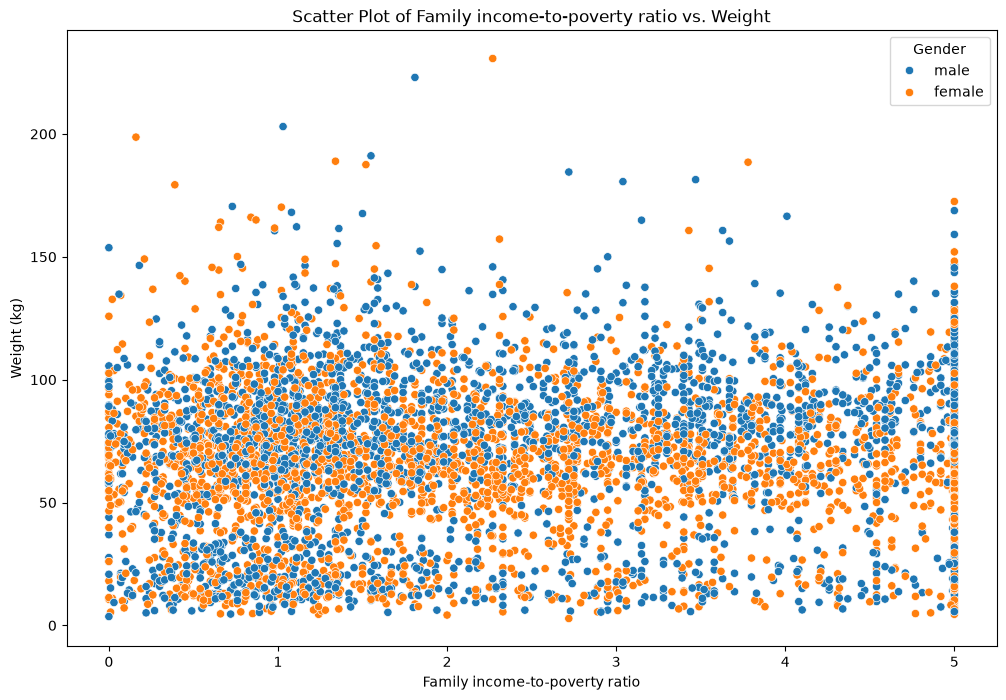

In [29]:
# Generate scatter plots for the poverty vs. weight
plt.figure(figsize=(12, 8))
sns.scatterplot(data=nhanes_deduplicated, x='Poverty', y='Weight', hue='Gender')
plt.title('Scatter Plot of Family income-to-poverty ratio vs. Weight')
plt.xlabel('Family income-to-poverty ratio')
plt.ylabel('Weight (kg)') 
plt.show()

### Income-to-Poverty Ratio and Weight
Lower income-to-poverty ratios indicate lower family income relative to the poverty guideline. The plot shows a wide range of weights across the ratios, without a clear overall linear trend.

The male and female groups overlap considerably. Because the data include children and adults, differences in age and height also affect weight. This plot alone does not establish whether income is associated with body weight.

In [30]:
# Create contingency tables for education vs. smoke_now
contingency_table = pd.crosstab(nhanes_deduplicated['Education'], nhanes_deduplicated['SmokeNow'])
display(contingency_table)

SmokeNow,No,Not applicable: under 20,Not asked: Smoke100 = No,Yes
Education,,,,
8th Grade,97,0,190,69
9 - 11th Grade,132,0,261,223
College Grad,291,0,856,94
High School,237,0,486,259
Not applicable: under 20,0,2114,0,0
Some College,324,0,780,308


### Education and Smoking
The table shows smoking responses across education groups. Some College has the largest number of current smokers (308), followed by High School (259). These are counts, not smoking rates, because the education groups differ in size.

The 2,114 participants under 20 are labeled “Not applicable.” “Not asked” identifies adults who reported fewer than 100 lifetime cigarettes and were therefore skipped for SmokeNow. This category remains separate from an observed “No” response.

Percentages with clearly defined denominators would be needed to compare smoking prevalence across education groups. This table alone does not establish that education causes differences in smoking.

In [31]:
# Create contingency tables for marital status vs. home_own
contingency_table2 = pd.crosstab(nhanes_deduplicated['MaritalStatus'], nhanes_deduplicated['HomeOwn'])
display(contingency_table2)

HomeOwn,Other,Own,Rent
MaritalStatus,,,
Divorced,12,245,183
LivePartner,11,131,226
Married,47,1861,534
NeverMarried,37,388,463
Not applicable: under 20,45,1207,862
Separated,6,51,78
Widowed,8,257,69


### Marital Status and Home Ownership
Owned homes are more common than rented homes among married, widowed, and divorced participants. Renting is more common among participants living with a partner, those never married, and those separated.

HomeOwn describes the household’s housing arrangement, not necessarily personal ownership by the participant. The under-20 group is labeled “Not applicable” because marital status was not reported for that age group.

These are counts from groups of different sizes. Percentages would support comparisons across groups, and the table does not establish that marital status causes differences in housing arrangements.

Variable Column name:
Age


Lower Bound,Upper Bound,Lower Limit,Upper Limit,Outliers Below Lower limit,Outliers Above Upper limit
-43.50,112.50,-33.94,104.79,0,0


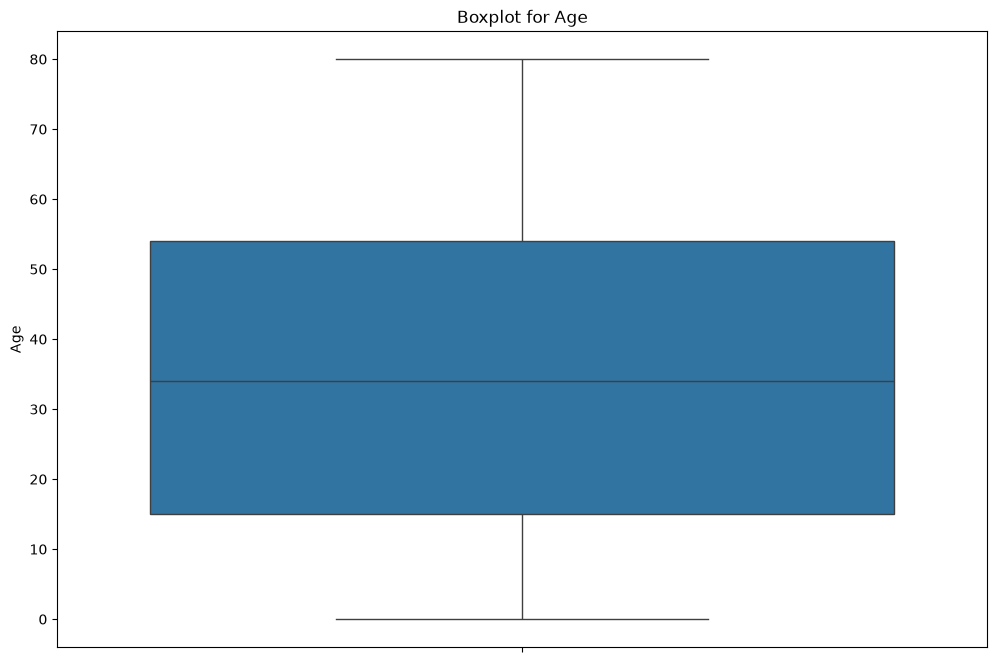

Variable Column name:
Pulse


Lower Bound,Upper Bound,Lower Limit,Upper Limit,Outliers Below Lower limit,Outliers Above Upper limit
37.00,109.00,36.93,110.32,0,27


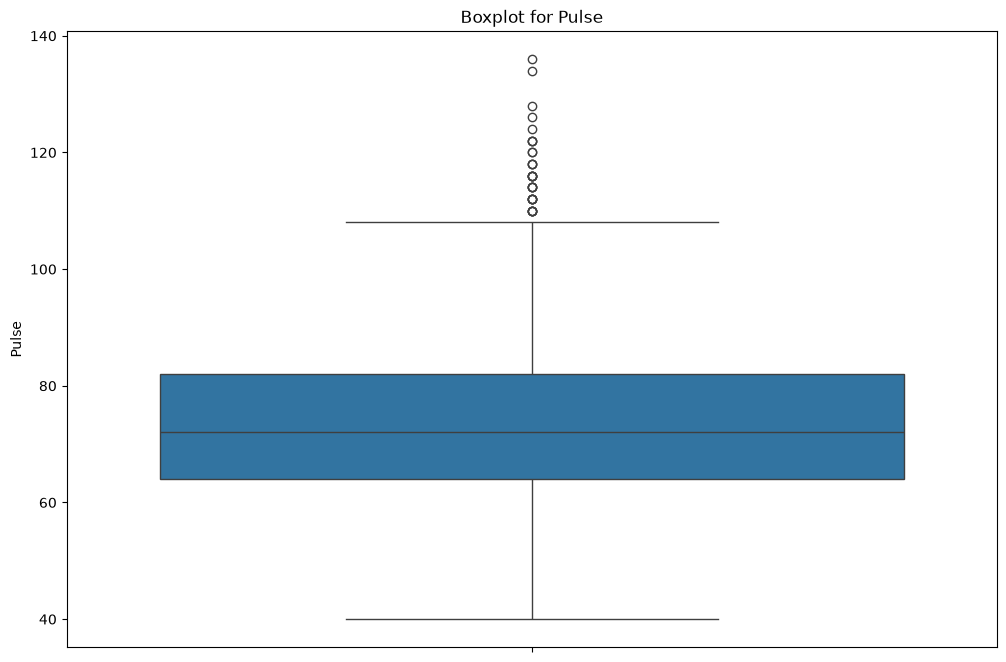

Variable Column name:
Height


Lower Bound,Upper Bound,Lower Limit,Upper Limit,Outliers Below Lower limit,Outliers Above Upper limit
128.20,201.00,96.90,223.81,141,0


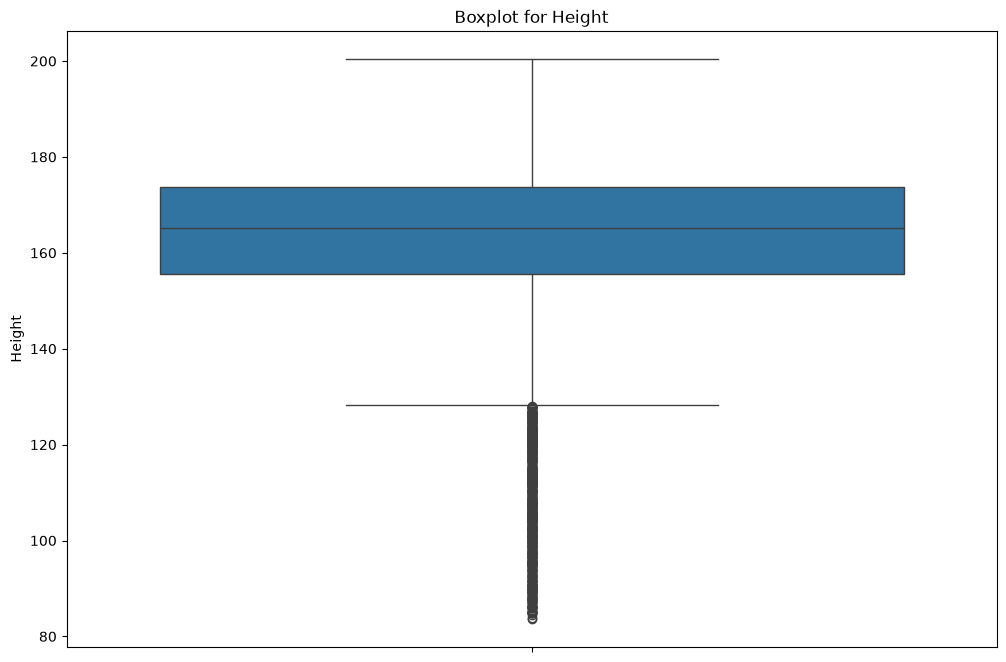

Variable Column name:
Weight


Lower Bound,Upper Bound,Lower Limit,Upper Limit,Outliers Below Lower limit,Outliers Above Upper limit
1.97,138.98,-20.85,159.01,0,32


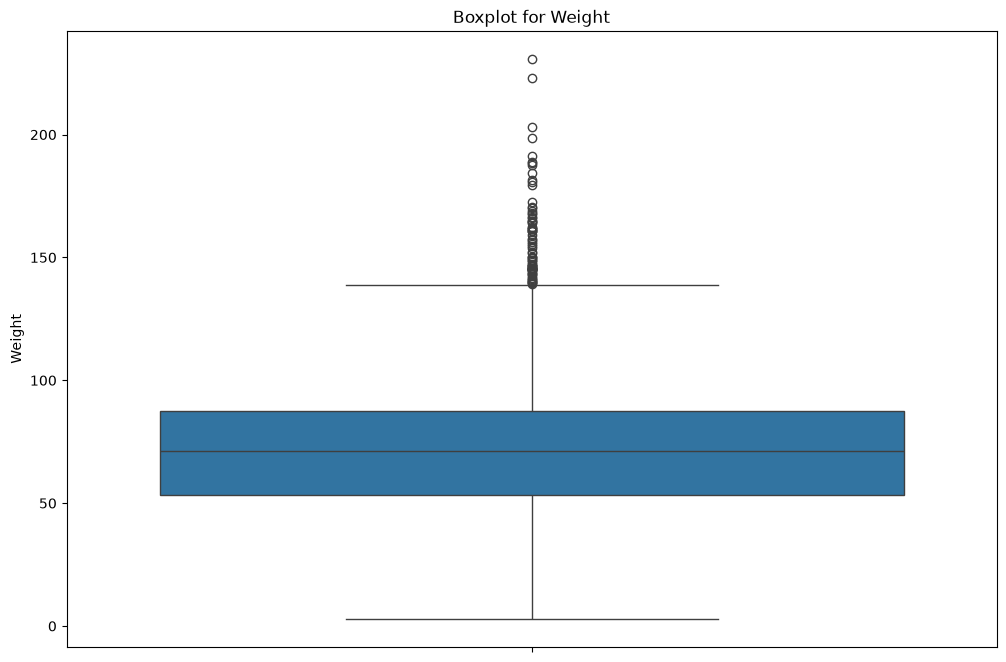

In [32]:
# Outlier examination: age, pulse, height, and weight
for col in ['Age', 'Pulse', 'Height', 'Weight']:
    Q1, Q3 = np.quantile(nhanes_deduplicated[col].dropna(), [0.25, 0.75])
    iqr = Q3 - Q1
    lower_bound = round(Q1 - 1.5 * iqr, 2) #IQR Lower/Upper Bound
    upper_bound = round(Q3 + 1.5 * iqr, 2) #IQR Lower/Upper Bound
    lower_limit = nhanes_deduplicated[col].mean() - 3 * nhanes_deduplicated[col].std() #Mean −/+ 3 SD
    upper_limit = nhanes_deduplicated[col].mean() + 3 * nhanes_deduplicated[col].std() #Mean −/+ 3 SD
    total_outlier_lower = nhanes_deduplicated[nhanes_deduplicated[col] < lower_limit].shape[0]
    total_outlier_upper = nhanes_deduplicated[nhanes_deduplicated[col] > upper_limit].shape[0]
    display(pd.DataFrame({'Variable Column name:':[col]}).style.hide(axis='index'))
    display(pd.DataFrame({'Lower Bound': [lower_bound], 'Upper Bound': [upper_bound], 
    'Lower Limit': [lower_limit], 'Upper Limit': [upper_limit],'Outliers Below Lower limit': [total_outlier_lower], 
        'Outliers Above Upper limit': [total_outlier_upper], })
    .style.format(precision=2).hide(axis='index') )
    plt.figure(figsize=(12, 8))
    sns.boxplot(data=nhanes_deduplicated[col])
    plt.title(f'Boxplot for {col}')
    plt.show()

### Outlier Examination
I used boxplots with the 1.5 × IQR rule to examine unusual observations and calculated mean ± 3 standard deviations to flag values beyond a ±3 SD z-score threshold.

- **Age:** No observations fall beyond either rule. Recorded age is capped at 80, representing ages 80 and older.
- **Pulse:** Twenty-seven observations exceed the upper 3-SD threshold of approximately 110.32 beats per minute.
- **Height:** There are 141 observations below approximately 96.90 cm. Since the dataset includes children, these require checking against age before considering removal.
- **Weight:** Thirty-two observations exceed approximately 159.01 kg and require further examination.

These thresholds flag unusual values, not confirmed errors. Negative lower limits are calculated boundaries, not negative measurements in the data. No observations are removed by this examination code.

In [33]:
# Examine high pulse readings by age group
pulse_upper_limit = nhanes_deduplicated['Pulse'].mean() + 3 * nhanes_deduplicated['Pulse'].std()

table_Pulse = pd.crosstab(nhanes_deduplicated['AgeDecade'], nhanes_deduplicated['Pulse'][nhanes_deduplicated['Pulse'] > pulse_upper_limit])
display(table_Pulse)

Pulse,112.0,114.0,116.0,118.0,120.0,122.0,124.0,126.0,128.0,134.0,136.0
AgeDecade,,,,,,,,,,,
0-9,1,1,0,0,0,0,0,0,0,1,0
10-19,0,0,1,1,0,1,0,1,0,0,0
20-29,1,0,1,1,0,0,1,0,1,0,0
30-39,1,1,0,0,0,0,0,0,0,0,0
40-49,1,1,2,0,1,2,0,0,0,0,0
60-69,1,0,1,1,0,0,0,0,0,0,0
70+,0,1,0,0,1,0,0,0,0,0,1


### Decision on Pulse Outliers
The 27 pulse readings above the 3-SD threshold range from 112 to 136 beats per minute and occur across several age groups. I retained them because the statistical threshold alone does not establish a recording error. The available data do not explain why these readings are high.

In [34]:
# Examine low height readings by exact age.
height_lower_limit = nhanes_deduplicated['Height'].mean() - 3 * nhanes_deduplicated['Height'].std()
table_height = pd.crosstab(nhanes_deduplicated['Age'], nhanes_deduplicated['Height'][nhanes_deduplicated['Height'] < height_lower_limit])
display(table_height)

Height,83.6,83.8,84.5,84.8,84.9,85.0,85.1,85.4,85.5,85.9,86.0,86.1,86.2,86.3,86.4,86.5,86.8,87.0,87.1,87.2,87.4,87.5,87.6,87.8,88.1,88.2,88.3,88.6,88.7,89.0,89.1,89.2,89.3,89.4,89.5,89.6,89.7,89.8,89.9,90.0,90.1,90.2,90.3,90.4,90.5,90.6,90.7,90.8,90.9,91.2,91.3,91.4,91.5,91.7,92.0,92.2,92.3,92.5,92.8,92.9,93.1,93.2,93.4,93.5,93.7,93.8,93.9,94.1,94.3,94.4,94.6,94.7,94.8,94.9,95.0,95.2,95.3,95.4,95.5,95.6,95.7,95.8,95.9,96.1,96.5,96.6,96.7,96.8
Age,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,1,1,1,1,2,1,3,1,1,1,2,1,4,1,1,1,1,1,2,1,1,1,2,3,2,2,2,2,1,3,1,1,1,1,2,2,1,2,0,0,1,1,1,1,1,1,2,2,1,1,1,1,3,2,1,1,4,1,1,0,1,1,1,0,1,2,0,1,1,1,0,1,0,1,0,2,1,0,0,1,0,2,0,0,3,1,2,1
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,2,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,1,0,1,1,0,1,0,1,0,2,1,1,1,2,2,3,0,1,0,2,2,2,0,0,1


### Decision on Height Outliers
The 141 heights below the lower 3-SD threshold belong to participants aged 2 or 3. The cutoff was calculated across children and adults together, so it flags these shorter children relative to the pooled dataset.

I retained these observations because their age provides a reasonable explanation for their shorter heights. Being outside the pooled threshold alone does not establish a measurement error.

In [35]:
# Examine weight outlier readings by age group
weight_upper_limit = nhanes_deduplicated['Weight'].mean() + 3 * nhanes_deduplicated['Weight'].std()

table_weight = pd.crosstab(nhanes_deduplicated['AgeDecade'], nhanes_deduplicated['Weight'][nhanes_deduplicated['Weight'] > weight_upper_limit])
display(table_weight)

Weight,159.1,160.6,160.7,161.5,161.7,162.0,162.2,164.1,164.5,164.9,165.0,166.1,166.5,167.6,168.1,168.8,170.2,170.5,172.5,179.3,180.6,181.4,184.5,187.5,188.5,188.9,191.1,198.7,203.0,223.0,230.7
AgeDecade,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10-19,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
20-29,0,1,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
30-39,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,1,1,0,1,1,0,0,1,0
40-49,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
50-59,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
60-69,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
70+,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### Decision on Weight Outliers
I excluded 32 records with weight above the calculated upper 3-SD threshold of approximately 159.01 kg, leaving 6,689 records. Missing weight values were retained. Weights above 159 kg are rare enough in this sample that a recording error is plausible, although not confirmed.

In [36]:
# Exclude weights above the upper 3-SD cutoff while retaining missing weight values.
nhanes_deduplicated = nhanes_deduplicated[(nhanes_deduplicated['Weight'] <= weight_upper_limit)| nhanes_deduplicated['Weight'].isna()].copy()
print(f'Rows after weight exclusion: {len(nhanes_deduplicated)}')

Rows after weight exclusion: 6689


## Sampling Distribution
I use BPSysAve, the combined systolic blood pressure measurement in mmHg, as the systolic blood pressure variable. I draw 10,000 random samples of 50 observations each, with replacement, from the available measurements in the filtered dataset.

I calculate each sample’s mean and examine the distribution of these 10,000 means to demonstrate sampling variability and the central limit theorem.

In [37]:
# Draw 10,000 samples of size 50 with replacement from observed BPSysAve values.
# Store each sample and its mean to examine the sampling distribution.

bp_values = nhanes_deduplicated['BPSysAve'].dropna()
sample_coltn = []
sample_means = []
rng = np.random.default_rng(42)

for i in range(10000):
    sample = rng.choice(bp_values, size=50, replace=True)
    sample_coltn.append(sample)
    sample_means.append(sample.mean())

sample_means = pd.Series(sample_means)

print(f'Number of samples: {len(sample_coltn)}')
print(f'Number of sample means: {len(sample_means)}')
display(sample_means.describe().round(2))

Number of samples: 10000
Number of sample means: 10000


count    10000.00
mean       117.92
std          2.48
min        110.54
25%        116.22
50%        117.86
75%        119.60
max        127.72
dtype: float64

### Summary of Sample Means
The 10,000 sample means have an average of 117.92 mmHg and a standard deviation of 2.48 mmHg. This standard deviation estimates the standard error for samples of size 50.

The middle 50% of sample means lie between 116.22 and 119.60 mmHg. The minimum and maximum, 110.54 and 127.72 mmHg, are sample averages—not individual blood-pressure readings.

In [38]:
# Compare the simulated sampling distribution with the source mean and expected SE.
display(pd.DataFrame({
    'Source data mean': [bp_values.mean()],
    'Mean of sample means': [sample_means.mean()],
    'SD of sample means': [sample_means.std()],
    'Expected standard error': [bp_values.std() / np.sqrt(50)]
}).style.hide(axis='index').format(precision=2))

Source data mean,Mean of sample means,SD of sample means,Expected standard error
117.93,117.92,2.48,2.49


### Comparison with the Source Data
The mean of the 10,000 sample means is 117.92 mmHg, close to the source-data mean of 117.93 mmHg. The simulated standard error is 2.48 mmHg, close to the expected value of 2.49 mmHg calculated using s/√50.

These results show that repeated sample averages centre near the source-data mean, with variability consistent with the standard-error formula. They do not establish the exact mean blood pressure of the wider population.

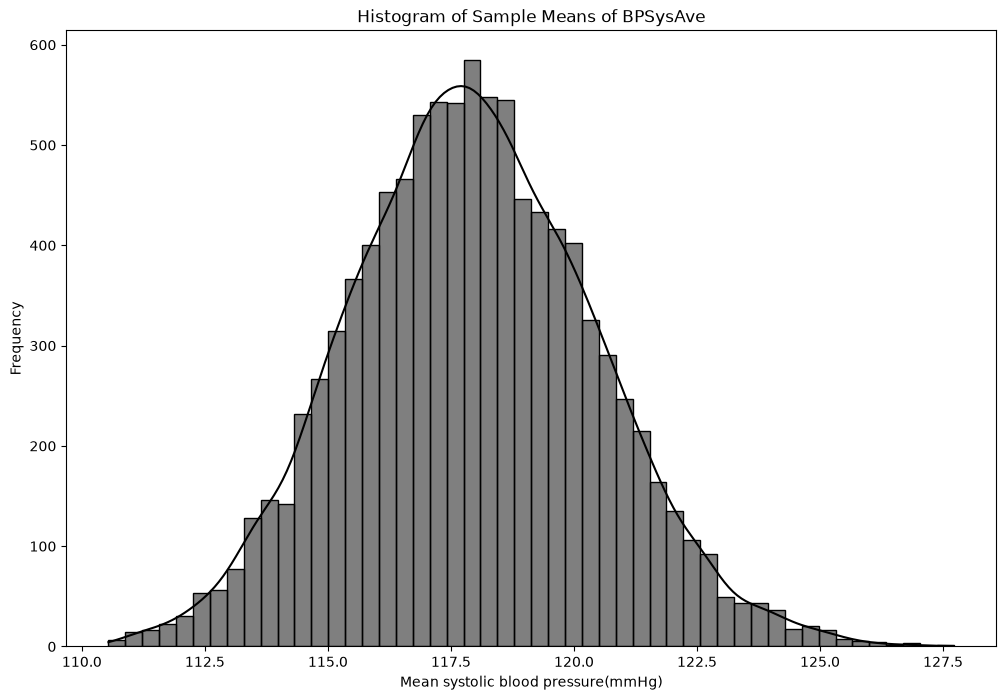

In [39]:
# histogram of this sampling distribution
plt.figure(figsize=(12, 8))
sns.histplot(sample_means, kde=True, bins=50, color='black')
plt.title('Histogram of Sample Means of BPSysAve')
plt.xlabel('Mean systolic blood pressure(mmHg)')
plt.ylabel('Frequency') 
plt.show()

### Interpretation of the Sampling Distribution
The distribution of 10,000 sample means is approximately bell-shaped, with a slight right tail and a centre near 118 mmHg. This is consistent with the central limit theorem for samples of size 50.

The sample means cluster around the source-data mean of 117.93 mmHg. Their standard deviation of 2.48 mmHg describes sampling variability, rather than variation in individual blood-pressure readings.

The simulation illustrates how sample means can estimate a population mean under appropriate sampling conditions. However, resampling this selected dataset cannot establish the exact wider-population mean or remove bias introduced by earlier exclusions.

## Research Questions

### Question 1
Among participants aged 20 or older, how do BMI and total cholesterol differ between those who report a diabetes diagnosis and those who do not?

### Question 2
Among participants aged 20 or older, how do reported diabetes prevalence and total cholesterol differ between current/former smokers combined and never smokers?

These comparisons describe associations within the analysed dataset, not cause-and-effect relationships.

In [40]:
# create smoking group by adding column 'smoking_Status' based on smoke100 and smokeNow columns 
# using the lifetime 100-cigarette threshold.
def smoking_status(row):
    if row['Age'] < 20:
        return 'Not applicable: under 20'
    elif row['Smoke100'] == 'Yes' and (row['SmokeNow'] == 'Yes' or row['SmokeNow'] == 'No'):
        return 'Current-Former smoker'
    elif row['Smoke100'] == 'No':
        return 'Never smoker'
    else:
        return 'Unknown'

nhanes_deduplicated['smoking_Status'] = nhanes_deduplicated.apply(
    smoking_status, axis=1
)

display(nhanes_deduplicated['smoking_Status'].value_counts(dropna=False))

smoking_Status
Never smoker                2553
Not applicable: under 20    2112
Current-Former smoker       2024
Name: count, dtype: int64

In [41]:
# Compare reported diabetes percentages between current/former and never smokers.
compare_table_Smoker = pd.crosstab(nhanes_deduplicated['smoking_Status'][nhanes_deduplicated['smoking_Status'].isin(['Current-Former smoker','Never smoker'])], 
                                   nhanes_deduplicated['Diabetes'], dropna=False,normalize='index')*100
display(compare_table_Smoker.style.format("{:.2f}"))

Diabetes,No,Yes
smoking_Status,,
Current-Former smoker,86.96,13.04
Never smoker,89.66,10.34


### Smoking History and Reported Diabetes
Reported diabetes prevalence is 13.04% among current/former smokers combined, compared with 10.34% among never smokers—a difference of 2.70 percentage points.

This is an unadjusted association within the analysed dataset. Differences in age or other characteristics may contribute, so the result does not establish that smoking caused diabetes.

In [42]:
# Compare current/former smokers and non smokers for Total Cholesterol
nhanes_deduplicated.loc[nhanes_deduplicated['Age'] >= 20].groupby('smoking_Status')['TotChol'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
smoking_Status,,,,
Current-Former smoker,1913,5.050518,4.97,1.102509
Never smoker,2399,5.052293,4.99,1.028510


### Smoking History and Total Cholesterol
Mean total cholesterol is almost identical between current/former smokers combined (5.051 mmol/L) and never smokers (5.052 mmol/L). Their medians are also similar: 4.97 and 4.99 mmol/L.

The comparison uses 1,913 and 2,399 observed cholesterol measurements, respectively. These summaries show little difference in average total cholesterol between the groups; they do not establish that smoking has no association with cholesterol.

In [43]:
# Compare BMI and total cholesterol by reported diabetes status among adults aged 20+.
nhanes_deduplicated.loc[
    nhanes_deduplicated['Age'] >= 20
].groupby('Diabetes')[['BMI', 'TotChol']].agg(
    ['count', 'mean', 'median', 'std']
)

BMI                             TotChol                           
         count       mean median       std   count      mean median       std
Diabetes                                                                     
No        4012  28.322398  27.35  6.168251    3827  5.081947   5.02  1.041957
Yes        521  31.893608  30.90  6.948296     485  4.811299   4.65  1.181342

### Diabetes Status, BMI, and Total Cholesterol
Adults reporting diabetes have a higher mean BMI (31.89 kg/m²) than those reporting no diabetes (28.32 kg/m²), a difference of 3.57 kg/m². The medians show the same pattern.

Mean total cholesterol is lower in the diabetes group: 4.81 versus 5.08 mmol/L, a difference of 0.27 mmol/L. The available data do not establish why this difference occurs.

Counts differ because missing BMI and cholesterol measurements are excluded separately. These comparisons describe associations, not causation, and may be affected by age differences and the earlier exclusion of high-weight participants.

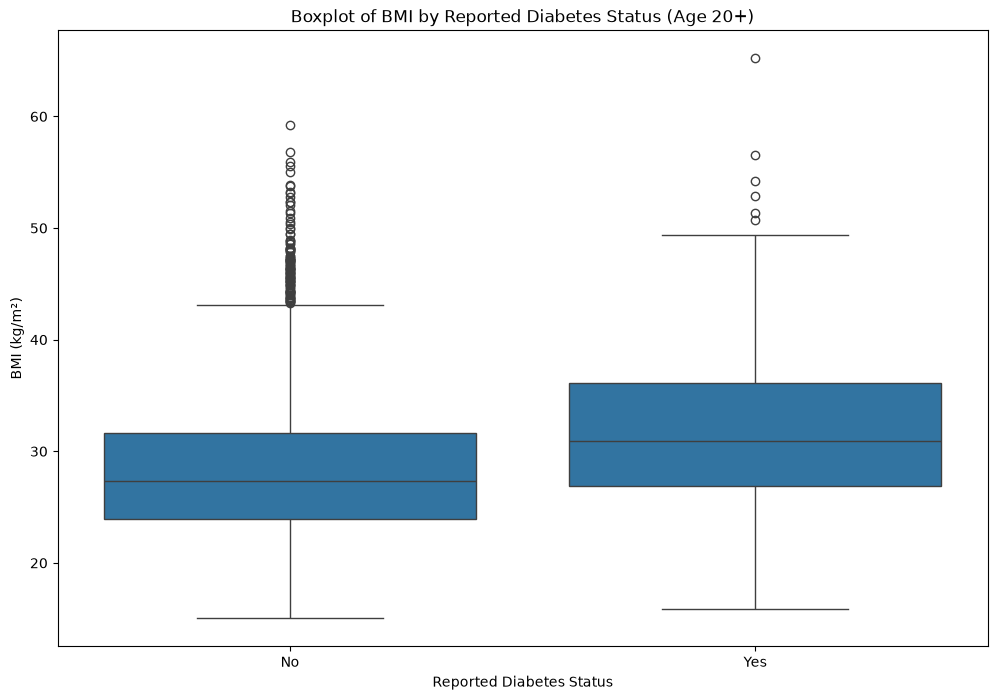

In [44]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=nhanes_deduplicated.loc[nhanes_deduplicated['Age'] >= 20], x='Diabetes', y='BMI')
plt.title('Boxplot of BMI by Reported Diabetes Status (Age 20+)')
plt.xlabel('Reported Diabetes Status')
plt.ylabel('BMI (kg/m²)')
plt.show()

### BMI by Reported Diabetes Status
The diabetes group has a higher median BMI (30.90 kg/m²) than the group reporting no diabetes (27.35 kg/m²). Its middle 50% of values also lies higher, although the distributions overlap substantially.

Both groups contain high values flagged by the boxplot’s IQR rule. These are not automatically measurement errors. The plot shows an association and does not establish causation.

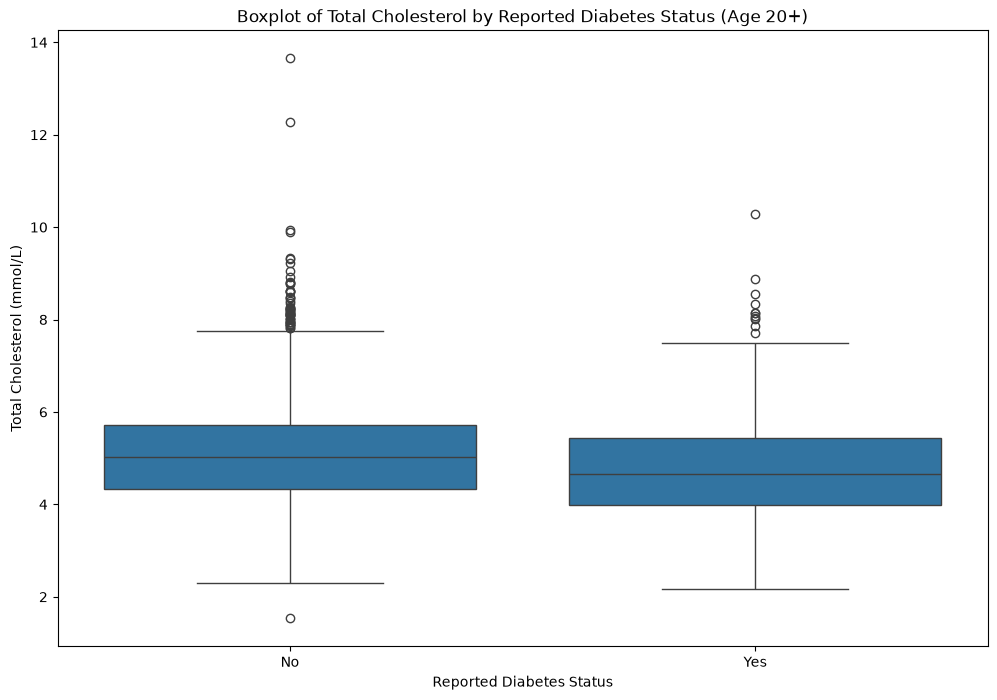

In [45]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=nhanes_deduplicated.loc[nhanes_deduplicated['Age'] >= 20], x='Diabetes', y='TotChol')
plt.title('Boxplot of Total Cholesterol by Reported Diabetes Status (Age 20+)')
plt.xlabel('Reported Diabetes Status')
plt.ylabel('Total Cholesterol (mmol/L)')
plt.show()

### Total Cholesterol by Reported Diabetes Status
The diabetes group has a lower median total cholesterol (4.65 mmol/L) than the group reporting no diabetes (5.02 mmol/L). However, the distributions overlap substantially, and both groups contain high values flagged by the boxplot.

This describes the analysed participants and does not establish why cholesterol differs between the groups.

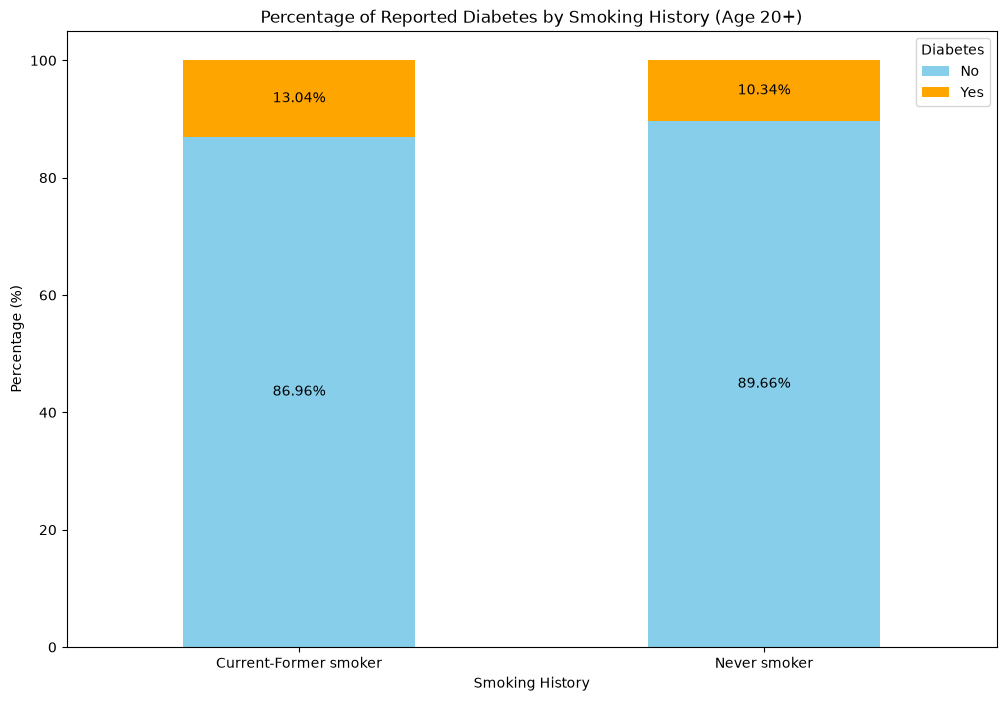

In [46]:
# percentage bar chart for diabetes by smoking history
ax = compare_table_Smoker.plot(kind='bar', stacked=True, color=['skyblue', 'orange'], figsize=(12, 8))
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', label_type='center')
plt.title('Percentage of Reported Diabetes by Smoking History (Age 20+)')
plt.xlabel('Smoking History')
plt.ylabel('Percentage (%)') 
plt.xticks(rotation=0)
plt.show()

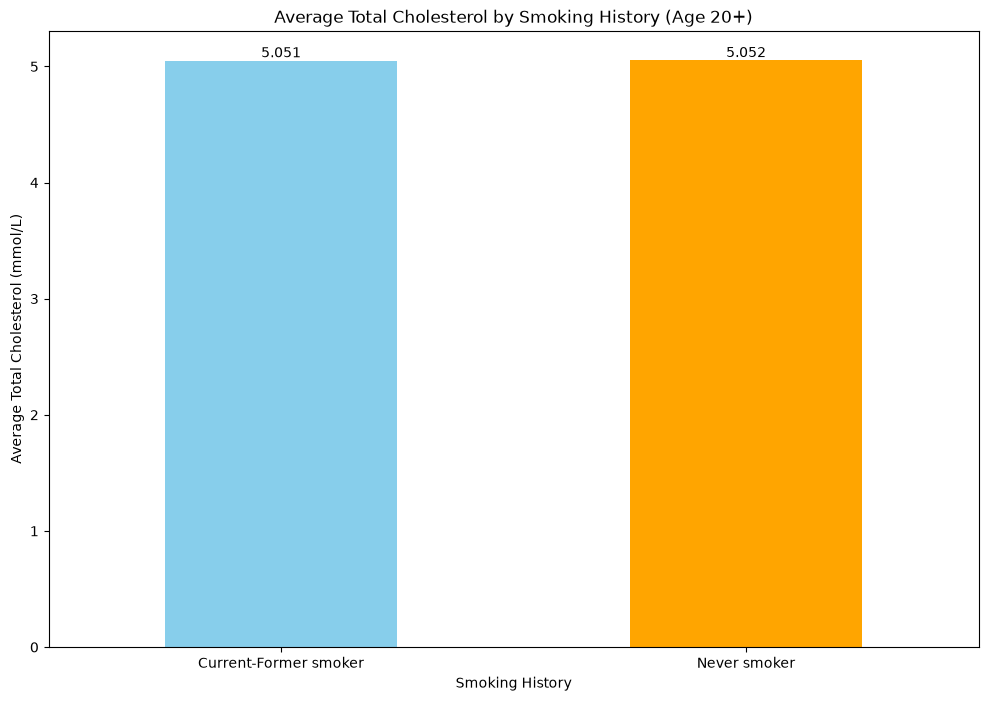

In [47]:
# Compare mean total cholesterol by smoking history among adults aged 20+
ax = nhanes_deduplicated.loc[nhanes_deduplicated['Age'] >= 20].groupby('smoking_Status')['TotChol'].mean().plot(kind='bar', color=['skyblue', 'orange'], figsize=(12, 8))
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='edge')
plt.title('Average Total Cholesterol by Smoking History (Age 20+)')
plt.xlabel('Smoking History')
plt.ylabel('Average Total Cholesterol (mmol/L)')   
plt.xticks(rotation=0) 
plt.show()

In [48]:
# binomial distribution for diabetes for current/former-smoker group
1-stats.binom.cdf(k=1,n=10,p =264/2024)

np.float64(0.38203823469533593)

In [49]:
# Sample diabetes responses from current/former smokers.
smoker_diabetes = nhanes_deduplicated.loc[(nhanes_deduplicated['Age'] >= 20) 
                                          &(nhanes_deduplicated['smoking_Status'] == 'Current-Former smoker'),
                                          'Diabetes'].dropna()

sample_counts_Smoker = []
rng = np.random.default_rng(42)

for i in range(10000):
    sample = rng.choice(smoker_diabetes, size=10, replace=True)
    sample_counts_Smoker.append((sample == 'Yes').sum())

# Percentage of sampled groups containing at least two Yes responses.
simulated_probability = (np.array(sample_counts_Smoker) >= 2).mean()

# Calculate the binomial probability using the same source data.
p_smoker = (smoker_diabetes == 'Yes').mean()
binomial_probability = 1 - stats.binom.cdf(1, 10, p_smoker)

display(pd.DataFrame({
    'Binomial probability (%)': [binomial_probability * 100],
    'Simulated proportion (%)': [simulated_probability * 100]
}).style.hide(axis='index').format(precision=2))

Binomial probability (%),Simulated proportion (%)
38.20,38.65


### Simulation Check
I generated 10,000 samples of 10 adults with replacement from the current/former-smoker group. Of these samples, 38.65% contained at least two participants reporting diabetes, close to the binomial probability of 38.20%.

The difference reflects simulation variability. These percentages describe groups of 10; the observed diabetes proportion among individual group members remains 13.04%.

In [50]:
# Sample diabetes responses from never smokers aged 20+.
never_diabetes = nhanes_deduplicated.loc[(nhanes_deduplicated['Age'] >= 20) 
                                         &(nhanes_deduplicated['smoking_Status'] == 'Never smoker'),'Diabetes'].dropna()

sample_counts_Never = []
rng = np.random.default_rng(42)

for i in range(10000):
    sample = rng.choice(never_diabetes, size=10, replace=True)
    sample_counts_Never.append((sample == 'Yes').sum())

simulated_probability_never = (np.array(sample_counts_Never) >= 2).mean()

p_never = (never_diabetes == 'Yes').mean()
binomial_probability_never = 1 - stats.binom.cdf(1, 10, p_never)

display(pd.DataFrame({
    'Binomial probability (%)': [binomial_probability_never * 100],
    'Simulated proportion (%)': [simulated_probability_never * 100]
}).style.hide(axis='index').format(precision=2))

Binomial probability (%),Simulated proportion (%)
27.71,28.15


For never smokers, 28.15% of the 10,000 simulated groups contained at least two participants reporting diabetes, compared with the binomial probability of 27.71%. The close agreement supports the calculation under the stated sampling assumptions.

In [51]:
#select BMI values for adults with Diabetes == 'Yes'
bmi_with_diabetes = nhanes_deduplicated.loc[(nhanes_deduplicated['Age'] >= 20) & (nhanes_deduplicated['Diabetes'] == 'Yes'), 'BMI'].dropna()
table_BMI_vs_diabetes = pd.DataFrame({'Proportion of BMI <= 30': [(bmi_with_diabetes<=30).mean()], 'Proportion of BMI > 30': [(bmi_with_diabetes>30).mean()]})
display(table_BMI_vs_diabetes.style.hide(axis='index').format(precision=4))

Proportion of BMI <= 30,Proportion of BMI > 30
0.4453,0.5547


In [52]:
#select BMI values for adults with Diabetes == 'No'
bmi_without_diabetes = nhanes_deduplicated.loc[(nhanes_deduplicated['Age'] >= 20) & (nhanes_deduplicated['Diabetes'] == 'No'), 'BMI'].dropna()
table_BMI_vs_no_diabetes = pd.DataFrame({'Proportion of BMI <= 30': [(bmi_without_diabetes<=30).mean()], 'Proportion of BMI > 30': [(bmi_without_diabetes>30).mean()]})
display(table_BMI_vs_no_diabetes.style.hide(axis='index').format(precision=4))

Proportion of BMI <= 30,Proportion of BMI > 30
0.6715,0.3285


### Empirical CDF Comparison
Among adults with observed BMI, 44.53% of those reporting diabetes have BMI ≤ 30, compared with 67.15% of those reporting no diabetes.

The complementary proportions with BMI > 30 are 55.47% and 32.85%, respectively—a difference of approximately 22.62 percentage points.

These proportions are calculated directly from observed data without assuming a theoretical distribution. They describe an association within the filtered dataset, not causation or future diabetes risk.

## Conclusion
This analysis examined the NHANES dataset through data preparation, exploratory analysis, outlier assessment, sampling distributions, and subgroup comparisons.

Adults reporting diabetes had higher average BMI but lower average total cholesterol than those reporting no diabetes. Reported diabetes prevalence was higher among current/former smokers combined than among never smokers, while average cholesterol was similar.

The sampling exercise illustrated variation in sample means. Binomial simulations and empirical CDF calculations cross-checked the subgroup proportions against theory and quantified the BMI gap directly from the data.

These findings describe the analysed dataset, not causal effects or future health risks. Missing measurements, age differences, removal of repeated selected records, and weight exclusions limit interpretation. The original data were preserved separately from the working datasets.